# 10 图像生成：在 CPU 上训练一个小型 DDPM

从 sklearn 自带 8×8 手写数字开始，观察**干净图 → 加噪矩阵 → 噪声预测 → 反向生成**。
这是真实的噪声预测与反向采样，采用很小的 CNN、短训练和低分辨率以适合 CPU；输出质量不能代表成熟图像生成模型。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cuda


## 1. 输入数据：归一化与张量布局

sklearn 的 digits 包含 8×8 灰度手写数字，像素原范围是 0～16。选 0、1、2 三类降低任务难度；不读取外部模型。训练和保留集分开。


训练张量 [N,C,H,W]: (429, 1, 8, 8)
一张输入的前 4×4 矩阵:
 [[-1.    -1.     0.25   0.625]
 [-1.    -1.     1.     1.   ]
 [-1.    -1.    -0.25  -0.875]
 [-1.    -1.    -1.    -1.   ]]


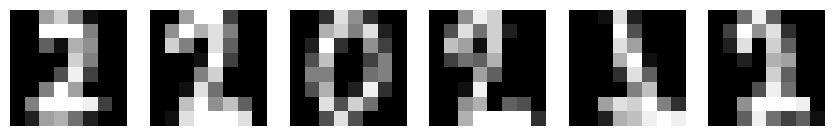

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/10_generation_inputs.png')

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()
images = digits.images[digits.target < 3].astype(np.float32)/8.0-1.0
train_images, heldout_images = train_test_split(images, test_size=0.2, random_state=42)
train_x = torch.from_numpy(train_images[:, None]).to(dev)
heldout_x = torch.from_numpy(heldout_images[:, None]).to(dev)
print("训练张量 [N,C,H,W]:", tuple(train_x.shape))
print("一张输入的前 4×4 矩阵:\n", train_images[0, :4, :4])
fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for ax, im in zip(axs, train_images[:6]):
    ax.imshow(im, cmap="gray", vmin=-1, vmax=1); ax.axis("off")
save_figure("10_generation_inputs")


## 2. 前向加噪

定义 $\beta_t$，$\alpha_t=1-\beta_t$，$\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$。
可直接采样：$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$，其中 $\epsilon\sim\mathcal N(0,I)$。
这里用 40 步和较大的最终噪声率，让末端足够接近高斯噪声；它是教学配置。


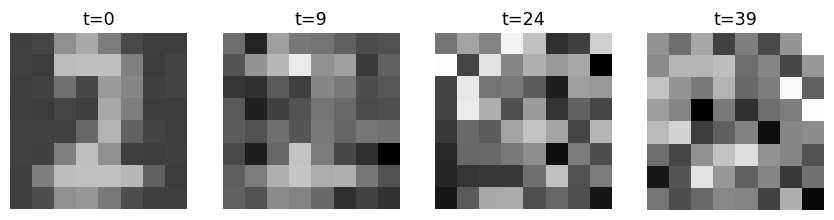

末端 alpha_bar: 0.004057906102389097
加噪后的 4×4:
 [[-0.17  0.55  0.06  1.79]
 [ 1.94 -0.94  1.55  0.1 ]
 [-0.95  1.61 -0.18 -0.09]
 [-0.95  1.66  0.73 -0.76]]


In [3]:
T = 40
betas = torch.linspace(0.001, 0.25, T, device=dev)
alphas = 1-betas
alpha_bar = torch.cumprod(alphas, 0)
def add_noise(clean, t, noise):
    a = alpha_bar[t][:, None, None, None]
    return a.sqrt()*clean+(1-a).sqrt()*noise

clean = train_x[:1].repeat(4, 1, 1, 1)
ts = torch.tensor([0, 9, 24, 39], device=dev)
noise = torch.randn_like(clean)
noisy = add_noise(clean, ts, noise)
fig, axs = plt.subplots(1, 4, figsize=(10, 3))
for ax, im, t in zip(axs, noisy.detach().cpu().numpy()[:, 0], ts.cpu().tolist()):
    ax.imshow(im, cmap="gray", vmin=-2, vmax=2); ax.set_title(f"t={t}"); ax.axis("off")
save_figure("10_generation_forward")
print("末端 alpha_bar:", alpha_bar[-1].item())
print("加噪后的 4×4:\n", np.round(noisy[2, 0, :4, :4].cpu().numpy(), 2))


## 3. 噪声预测网络

网络输入是 $x_t$ 和时间 $t$，输出与图像同形状的预测噪声。时间编码拼成一个额外通道。

形状怎么读：原图与预测噪声均为 `[N,1,8,8]`，表示 N 张单通道 8×8 图；时间通道与噪声图拼接后，网络实际接收 `[N,2,8,8]`。显示的 4×4 矩阵是某张图左上角的局部，不能当成整张 8×8 图。原始像素 0～16 经 `像素/8-1` 映射到 [-1,1]；加入高斯噪声后允许超出该范围。
损失 $\mathbb E\|\epsilon-\epsilon_\theta(x_t,t)\|^2$，目标是随机加入的**真实噪声**。


初期/末期平均训练损失: 0.5719089061021805 0.14838569909334182


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 27493 (\N{CJK UNIFIED IDEOGRAPH-6B65}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22122 (\N{CJK UNIFIED IDEOGRAPH-566A}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 22768 (\N{CJK UNIFIED IDEOGR

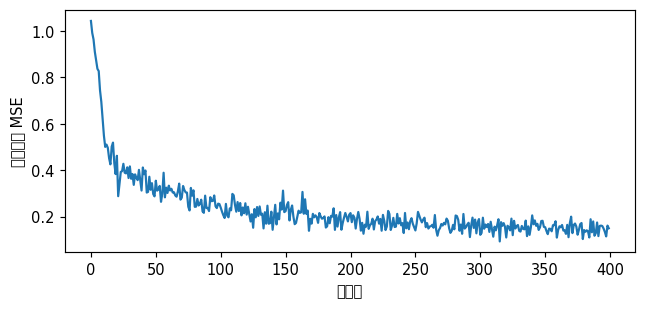

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/10_generation_loss.png')

In [4]:
class TinyNoisePredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(2, 32, 3, padding=1), nn.SiLU(),
                                 nn.Conv2d(32, 32, 3, padding=1), nn.SiLU(),
                                 nn.Conv2d(32, 32, 3, padding=1), nn.SiLU(),
                                 nn.Conv2d(32, 1, 3, padding=1))
    def forward(self, x, t):
        time_channel = (t.float()/(T-1))[:, None, None, None].expand(-1, 1, 8, 8)
        return self.net(torch.cat([x, time_channel], dim=1))

model = TinyNoisePredictor().to(dev)
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)
steps = int(os.environ.get("CV_DIFFUSION_STEPS", "400"))
losses = []
model.train()
for step in range(steps):
    ids = torch.randint(len(train_x), (64,), device=dev)
    x0 = train_x[ids]
    t = torch.randint(T, (len(x0),), device=dev)
    epsilon = torch.randn_like(x0)
    xt = add_noise(x0, t, epsilon)
    loss = F.mse_loss(model(xt, t), epsilon)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
    losses.append(loss.item())
print("初期/末期平均训练损失:", np.mean(losses[:30]), np.mean(losses[-30:]))
plt.figure(figsize=(7, 3)); plt.plot(losses); plt.xlabel("训练步"); plt.ylabel("噪声预测 MSE")
save_figure("10_generation_loss")


## 4. 保留集检查：网络是否学到去噪

与“始终预测零噪声”比较同一批保留图的噪声 MSE。它衡量去噪能力，不等于 FID 或人类视觉质量。


In [5]:
model.eval()
with torch.no_grad():
    val_t = torch.full((len(heldout_x),), T//2, device=dev, dtype=torch.long)
    val_e = torch.randn_like(heldout_x)
    val_xt = add_noise(heldout_x, val_t, val_e)
    pred_e = model(val_xt, val_t)
    val_mse = F.mse_loss(pred_e, val_e).item()
    zero_mse = val_e.square().mean().item()
print(f"保留集噪声 MSE={val_mse:.4f}; 零预测基线={zero_mse:.4f}")
assert np.isfinite(val_mse)


保留集噪声 MSE=0.0748; 零预测基线=1.0112


## 5. 从纯噪声开始反向采样

DDPM 反向均值：$\mu_\theta=\alpha_t^{-1/2}(x_t-\beta_t\epsilon_\theta/\sqrt{1-\bar\alpha_t})$。
采用后验方差 $\tilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$，最后一步不再加噪。
为了小模型稳定，先估计并截断 $\hat x_0$ 到数据范围，再计算等价后验均值。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21453 (\N{CJK UNIFIED IDEOGRAPH-53CD}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21453 (\N{CJK UNIFIED IDEOGRAPH-53CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21521 (\N{CJK UNIFIED IDEOGRAPH-5411}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


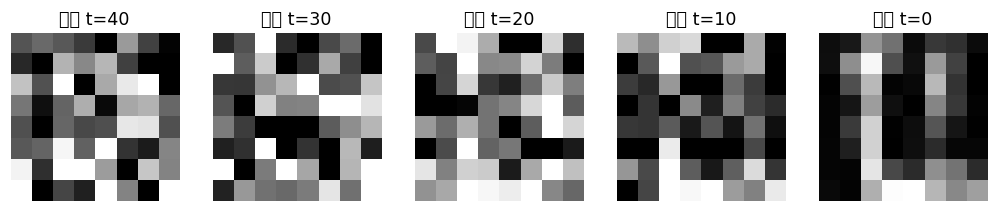

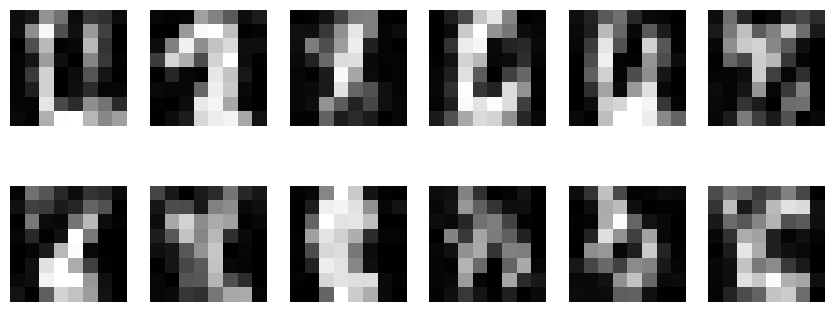

生成输出 4×4:
 [[-0.89 -0.81  0.16 -0.11]
 [-0.89  0.11  0.93 -0.38]
 [-0.99 -0.38  0.45 -0.97]
 [-0.96 -0.84  0.23 -0.88]]


In [6]:
snapshots = {}
with torch.no_grad():
    x = torch.randn(12, 1, 8, 8, device=dev)
    snapshots[T] = x[0, 0].cpu().numpy().copy()
    for t in reversed(range(T)):
        tt = torch.full((len(x),), t, device=dev, dtype=torch.long)
        eps = model(x, tt)
        a_bar = alpha_bar[t]
        prev_bar = alpha_bar[t-1] if t > 0 else torch.tensor(1., device=dev)
        x0_est = ((x-(1-a_bar).sqrt()*eps)/a_bar.sqrt()).clamp(-1, 1)
        mean = betas[t]*prev_bar.sqrt()/(1-a_bar)*x0_est + (1-prev_bar)*alphas[t].sqrt()/(1-a_bar)*x
        variance = betas[t]*(1-prev_bar)/(1-a_bar)
        x = mean + variance.sqrt()*torch.randn_like(x) if t > 0 else mean
        if t in [30, 20, 10, 0]:
            snapshots[t] = x[0, 0].cpu().numpy().copy()
generated = x.cpu().numpy()[:, 0]
fig, axs = plt.subplots(1, 5, figsize=(12, 3))
for ax, (t, im) in zip(axs, snapshots.items()):
    ax.imshow(im, cmap="gray", vmin=-1, vmax=1); ax.set_title(f"反向 t={t}"); ax.axis("off")
save_figure("10_generation_process")
fig, axs = plt.subplots(2, 6, figsize=(10, 4))
for ax, im in zip(axs.flat, generated):
    ax.imshow(im, cmap="gray", vmin=-1, vmax=1); ax.axis("off")
save_figure("10_generation_outputs")
print("生成输出 4×4:\n", np.round(generated[0, :4, :4], 2))


## 6. 理解局限与练习

本课没有文本条件，也没有潜空间编码器，不能直接称为 Stable Diffusion。短训练可能生成模糊或难辨认的数字；请把实际结果与训练数据并排看，不能把训练图当生成图。

练习：把 CV_DIFFUSION_STEPS 改为 800；比较固定随机种子下的生成质量和耗时。扩展到全部十类后，为什么训练更难？

主要来源：[DDPM 原论文](https://arxiv.org/abs/2006.11239)、[作者代码](https://github.com/hojonathanho/diffusion)、[sklearn digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)。本课为独立教学简化实现。
